# This notebook explores the IBM Quantum Platform Build Your Own Quantum Computer Tutorial

## Basic Package Imports

In [ ]:
# Core Qiskit imports
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# IBM Runtime specific imports
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

# DotEnv and OS
from dotenv import load_dotenv
import os

## Environment Check

In [2]:
import sys

import qiskit
import qiskit_aer
import qiskit_ibm_runtime
import pylatexenc

print("Python:", sys.version.split()[0])
print("qiskit:", qiskit.__version__)
print("qiskit-aer:", qiskit_aer.__version__)
print("qiskit-ibm-runtime:", qiskit_ibm_runtime.__version__)
print("pylatexenc:", pylatexenc.__version__)

Python: 3.11.18
qiskit: 2.6.2
qiskit-aer: 0.18.2
qiskit-ibm-runtime: 0.52.1
pylatexenc: 2.11


## Basic Terminology

Superposition: A fundamental principle that allows quantum systems to exist in multiple states simulaneously. Once read, it will be measured as either 0 or 1.

Bell State: A type of maximally entangled quantum state involving two qubits that has non-classical correlations. Measuring one affects the state of the other.

Quantum Entanglement: A phenomenon in quantum mechanics where two or more particles become interconnected such that their states are correlated and one particle cannot be described independently of the state of another.

## Tutorial

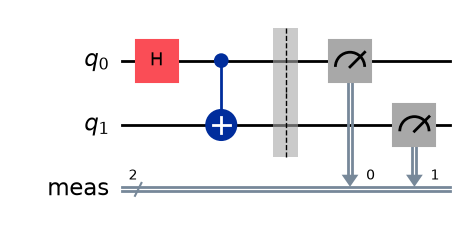

In [3]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

bell.measure_all()
bell.draw("mpl")

In [4]:
def run_circuit_and_get_counts(circuit, backend, shots=1000):
    """
    Runs a quantum circuit on a specified backend and returns the measurement counts.

    Args:
        circuit (QuantumCircuit): The quantum circuit to run.
        backend: The Qiskit backend (real device or simulator).
        shots (int): The number of shots to run the circuit.

    Returns:
        dict: A dictionary of measurement counts.
    """
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(circuit)

    sampler = Sampler(mode=backend)

    job = sampler.run([isa_circuit], shots=shots)
    result = job.result()

    return result[0].data.meas.get_counts()

In [ ]:

import os
from dotenv import load_dotenv
from qiskit_ibm_runtime import QiskitRuntimeService


def join_least_busy_backend(min_num_qubits=127):
    """
    Connects to IBM Quantum and returns the least busy
    operational, non-simulator backend.

    Args:
        min_num_qubits (int): Minimum number of physical qubits.

    Returns:
        Backend: Selected IBM Quantum backend.
    """
    load_dotenv()

    IBM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN")

    if not IBM_TOKEN:
        raise ValueError("IBM_QUANTUM_TOKEN not found in .env")

    # Initialize service using the environment token
    service = QiskitRuntimeService(
        channel="ibm_quantum_platform",
        token=IBM_TOKEN,
    )

    # Find least busy physical backend
    backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=min_num_qubits,
    )

    print(f"Connected to backend: {backend.name}")
    print(f"Number of qubits: {backend.num_qubits}")

    return backend

backend = join_least_busy_backend()

qiskit_runtime_service._discover_account:WARNING:2026-11-16 22:46:28,168: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-16 22:46:31,279: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-16 22:46:31,723: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-16 22:46:34,213: Using instance: open-instance, plan: open


Connected to backend: ibm_fez
Number of qubits: 156


<IBMBackend('ibm_fez')>

qiskit_runtime_service.backends:WARNING:2026-11-16 22:31:40,965: Using instance: open-instance, plan: open


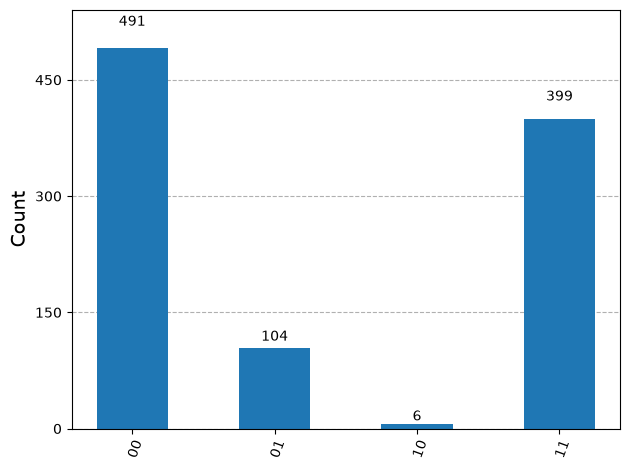

In [8]:
counts = run_circuit_and_get_counts(bell, backend, shots=1000)
plot_histogram(counts)

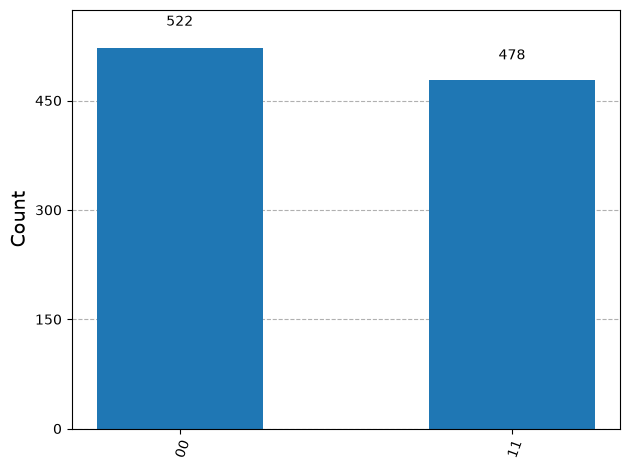

In [9]:
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)

plot_histogram(counts)

## Challenge: Design the Three Other Bell States

### First Design: X before H

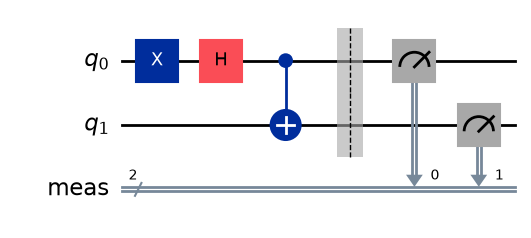

In [12]:
bell = QuantumCircuit(2)
bell.x(0)
bell.h(0)
bell.cx(0, 1)

bell.measure_all()
bell.draw("mpl")

qiskit_runtime_service._discover_account:WARNING:2026-11-16 22:47:46,222: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-16 22:47:48,565: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-16 22:47:48,720: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-16 22:47:51,137: Using instance: open-instance, plan: open


Connected to backend: ibm_fez


qiskit_runtime_service.backends:WARNING:2026-11-16 22:47:54,444: Using instance: open-instance, plan: open


Number of qubits: 156


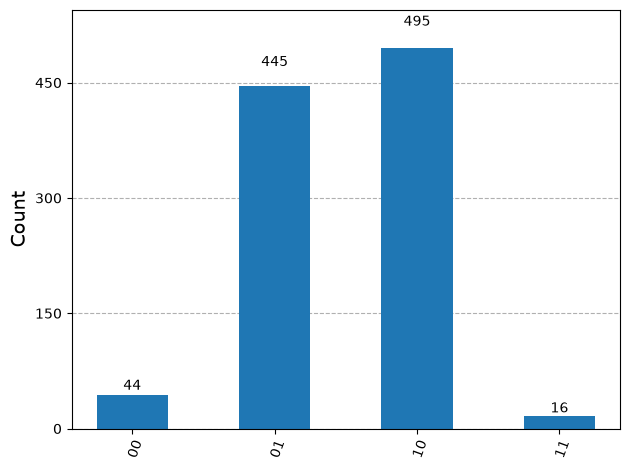

In [24]:
backend = join_least_busy_backend()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)
plot_histogram(counts)

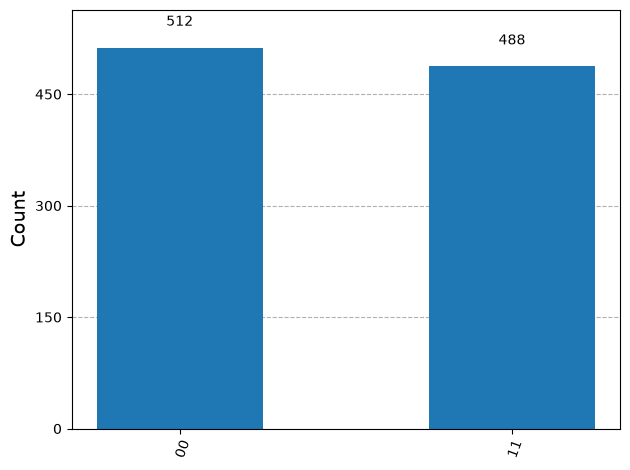

In [14]:
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)

plot_histogram(counts)

### Second Design: Both with X's

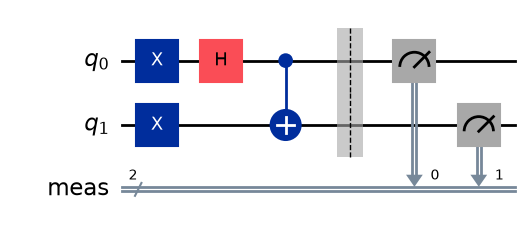

In [15]:
bell = QuantumCircuit(2)
bell.x(0)
bell.h(0)
bell.x(1)
bell.cx(0, 1)

bell.measure_all()
bell.draw("mpl")

qiskit_runtime_service._discover_account:WARNING:2026-11-16 22:48:11,507: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-16 22:48:14,412: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:14,797: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:16,908: Using instance: open-instance, plan: open


Connected to backend: ibm_fez
Number of qubits: 156


qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:19,778: Using instance: open-instance, plan: open


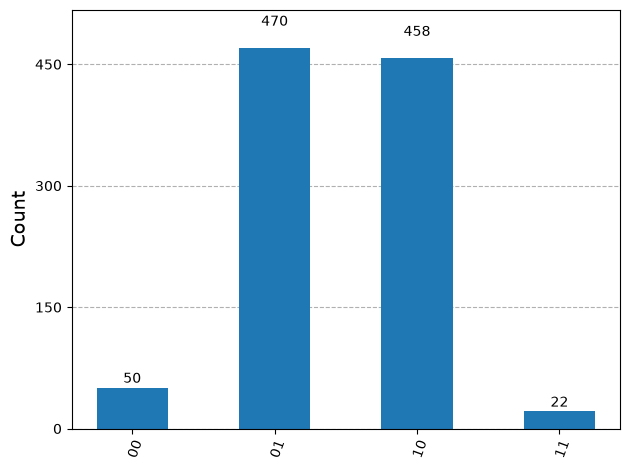

In [25]:
backend = join_least_busy_backend()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)
plot_histogram(counts)

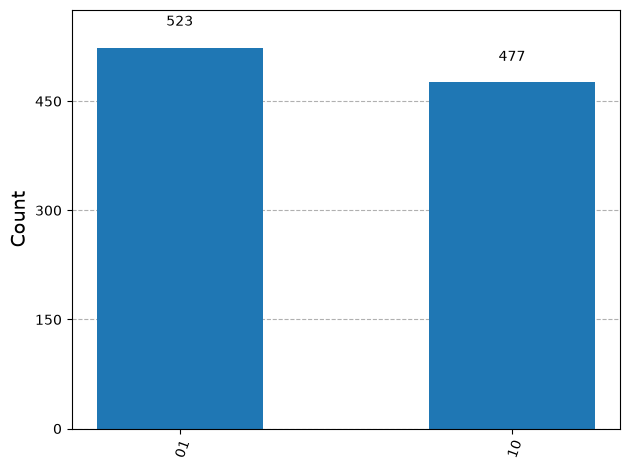

In [17]:
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)

plot_histogram(counts)

### Third Design: X on Qubit without H

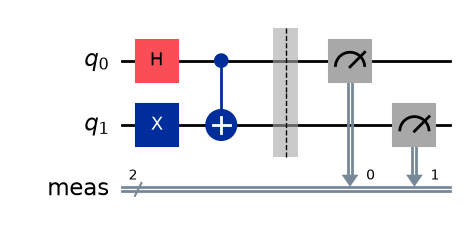

In [18]:
bell = QuantumCircuit(2)
bell.h(0)
bell.x(1)
bell.cx(0, 1)

bell.measure_all()
bell.draw("mpl")

qiskit_runtime_service._discover_account:WARNING:2026-11-16 22:48:35,505: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-16 22:48:38,322: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:38,761: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:40,360: Using instance: open-instance, plan: open


Connected to backend: ibm_fez


qiskit_runtime_service.backends:WARNING:2026-11-16 22:48:41,649: Using instance: open-instance, plan: open


Number of qubits: 156


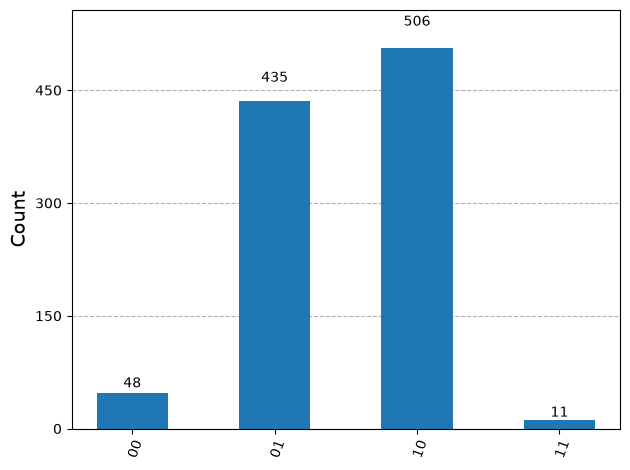

In [26]:
backend = join_least_busy_backend()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)
plot_histogram(counts)

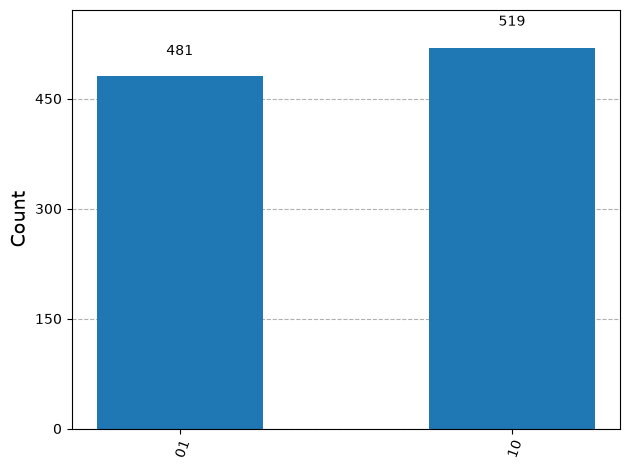

In [20]:
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)

plot_histogram(counts)